# Анализ данных в Python. Финальный экзамен

**Баев Артем, MAF**

Данные: записи событий матчей плей-офф НХЛ сезона 2025/2026 (`NHL-playoffs-2026.xlsx`).
Для запуска рядом с тетрадкой должны лежать файл с данными и `rink.py` (рисование площадки).

В конце тетрадки есть пункт 22 (свой вопрос) и небольшой дополнительный раздел сверх задания.

In [3]:
#импортируем нужные библиотеки

# для анализа данных
import numpy as np 
import pandas as pd

# для рисования графиков
import matplotlib.pyplot as plt
import seaborn as sns

from rink import plot_rink

sns.set_context('notebook')
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_colwidth', 100)   # чтобы описания матчей не обрезались

## 1. Загрузка данных

Первая колонка в файле — просто номер строки, делаю её индексом, тогда получается 38 колонок, как в примере.

In [6]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)

print(events.shape)
events.iloc[:10, [2, 3, 4, 9, 12]] #берем срез по стобцам и строкам

(29710, 38)


,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Посмотрим, какие вообще события есть в данных и сколько их.

In [16]:
print(events['Game ID'].nunique(), 'матчей') #смотрим на уникальные события
events['Play Type'].value_counts() #Типы событий на хоккейной площадке

82 матчей


Play Type
hit                5621
faceoff            4995
shot-on-goal       4137
stoppage           3958
blocked-shot       2798
missed-shot        2643
giveaway           2604
penalty             804
takeaway            779
goal                486
period-start        272
period-end          272
delayed-penalty     259
game-end             82
Name: count, dtype: int64

## 2. Сводная таблица по играм

Счёт в данных накопленный, поэтому итоговый счёт матча — это максимум `Cumulated ... Score` по игре.
Число овертаймов определяю по номеру последнего периода: 3 — основное время, 4 — один овертайм, 5 — два и т.д.

In [19]:
grouped = events.groupby('Game ID') 

games = grouped[['Date', 'Away Team', 'Home Team']].first()
games['Away Score'] = grouped['Cumulated Away Score'].max() #совокупный счет у гостей
games['Home Score'] = grouped['Cumulated Home Score'].max() #совокупный счет у местных

#теперь определим количество овертаймов 
# сделаем функцию 
def outcome(last_period): 
    if last_period <= 3:
        return 'Final'
    elif last_period == 4:
        return 'Final/OT'
    else:
        return 'Final/' + str(last_period - 3) + 'OT'


games['Outcome'] = grouped['Period'].max().apply(outcome)

print(games.columns)
games.iloc[-5:, -4:] #смотрим на новые столбцы и нижние строки, чтобы визуально оценить правильность сделанного

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='object')


,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


In [21]:
#финальная проверка, что кол-во игр бьется

print(games['Outcome'].value_counts())
# в плей-офф не может быть ничьи; проверим это тоже
print('Ничьих:', (games['Away Score'] == games['Home Score']).sum())

Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64
Ничьих: 0


## 3. Функция `gameInfo()`

In [22]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return f"{g['Home Team']} - {g['Away Team']} ({g['Home Score']} - {g['Away Score']}, {g['Outcome']}, {g['Date']})"


print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## 4. Сколько шайб забито в каждой игре

In [26]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

count   82.000
mean     5.927
std      2.260
min      1.000
25%      5.000
50%      6.000
75%      7.000
max     15.000
Name: Total Score, dtype: float64

## 5. Гистограмма числа голов

Часть значений у нас отсутствует (не забивало столько голов) ---> эти "пропуски" на оси Ох не отобразятся.

Для лучшей визуалиции сделаем более базированно.

Через `order` задаем все значения от 1 до 15, чтобы на оси были и те, которых не было ни разу (12–14 голов).

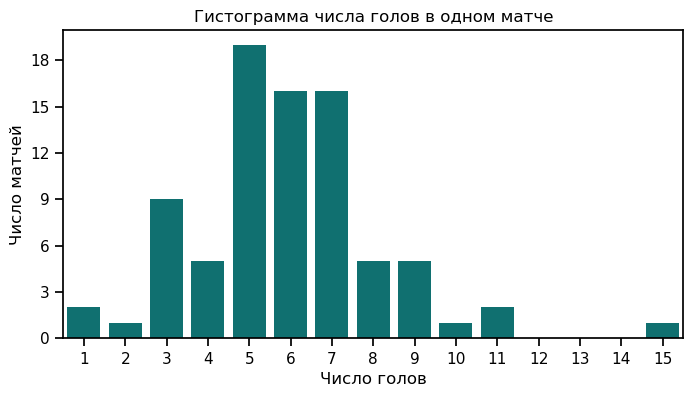

Total Score
1      2
2      1
3      9
4      5
5     19
6     16
7     16
8      5
9      5
10     1
11     2
15     1
Name: count, dtype: int64


In [36]:
plt.figure(figsize=(8, 4))
sns.countplot(x=games['Total Score'], order=list(range(1, 16)), color='teal')
plt.yticks(range(0, 21, 3))
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.title('Гистограмма числа голов в одном матче')
plt.show()

print(games['Total Score'].value_counts().sort_index())

**Комментарий.** Распределение одновершинное и немного скошено вправо. Чаще всего за матч забивали 5 голов (19 матчей),
6 и 7 голов — по 16 матчей. Среднее (5.93) и медиана (6) почти совпадают. Малорезультативных игр мало: с 1–2 голами всего три матча.
Справа длинный хвост: 10–11 голов было в трёх матчах, и есть один явный выброс — 15 голов (Колорадо – Миннесота 9:6).

## 6. Самые нерезультативные и самые результативные игры

In [38]:
min_score = games['Total Score'].min()
max_score = games['Total Score'].max()

least = [gameInfo(i) for i in games[games['Total Score'] == min_score].index]
most = [gameInfo(i) for i in games[games['Total Score'] == max_score].index]

print(least)
print(most)

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


Оба самых нерезультативных матча (по одному голу) закончились в овертайме со счётом 1:0.

## 7. Сколько игроков участвовало в каждой игре

Для каждой игры собираем множество всех фамилий из колонок с составами на льду (#1–#6 у обеих команд) плюс колонки вратарей —
вратари и так попадают в #1–#6,чтобы точно никого не потерять. Пустые ячейки (NaN) дропаем.

In [47]:
player_cols = ([f"Away Team's Player on the Ice #{i}" for i in range(1, 7)] +
               [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)] +
               ["Away Team's Goalie", "Home Team's Goalie"])

player_count = {}
for game_id, df in events.groupby('Game ID'):
    players = set() # число игроков зададим множеством чтобы не зафиксировать когото 2 раза
    for col in player_cols:
        players = players | set(df[col].dropna()) # накапливаем во множестве одинаковых игроков
    player_count[game_id] = len(players)

games['Player Count'] = pd.Series(player_count)
games['Game Info'] = games.index.map(gameInfo)

print(games['Player Count'].value_counts())
games.loc[games['Player Count'] == games['Player Count'].max(), ['Game Info', 'Player Count']]

Player Count
38    73
39     8
40     1
Name: count, dtype: int64


,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Final, 2026-05-16)",40


Таким образом, в матче Montréal Canadiens - Buffalo Sabres 2026-05-16 успело сыграть 40 игроков. То есть во время игры обе команды поменяли как весь основной состав, так и вратарей.

## 8. Расстояние до ворот для бросков

Сначала определим, в какие ворота бьют. Если ворота хозяев слева (`left`), то хозяева бьют в правые ворота ($X = 89$),
гости — в левые ($X = -89$), и наоборот. Дальше — расстояние до ближайшей точки створа (штанги в $y = \pm 3$) по формуле из задания.

In [50]:
shot_types = ['shot-on-goal', 'goal', 'missed-shot'] #удары по воротам

#запишем откуда херачим в ворота
def shot_length(row):
    x = row['X Coordinate on the Ice Rink']
    y = row['Y Coordinate on the Ice Rink']
    home_shot = row['Team Making the Play'] == row['Home Team'] #бросают гости или хозяева

    # координата ворот, в которые бьют
    if row["Home Team's Defending Side"] == 'left':
        if home_shot:
            X = 89
        else:
            X = -89
    else:
        if home_shot:
            X = -89
        else:
            X = 89
# расстояние до ворот
    if y < -3:
        return np.sqrt((x - X)**2 + (y + 3)**2)
    elif y <= 3:
        return abs(x - X)
    else:
        return np.sqrt((x - X)**2 + (y - 3)**2)


is_shot = events['Play Type'].isin(shot_types)
events.loc[is_shot, 'Shot Length'] = events[is_shot].apply(shot_length, axis=1)

events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


Проверка, что стороны не перепутаны: броски из зоны атаки должны быть ближе 89 футов, а из своей зоны — дальше.

In [13]:
events[is_shot].groupby('Play Zone')['Shot Length'].describe()

,count,mean,std,min,25%,50%,75%,max
Play Zone,,,,,,,,
Defensive,164.000,157.122,19.730,114.018,142.527,159.278,173.094,188.215
Neutral,206.000,86.081,11.222,66.000,76.538,85.607,93.622,117.720
Offensive,6896.000,31.001,18.267,0.000,14.560,30.249,44.844,74.431


Всё сходится: из зоны атаки максимум 74 фута, из своей зоны — от 114 футов.

## 9. Распределение длины точных и неточных бросков

Точные броски — `shot-on-goal` и `goal`, неточные — `missed-shot`. Неточных бросков почти в два раза меньше, поэтому
обычные частоты сравнивать нельзя. В `displot` можно поставить `stat='density'` и `common_norm=False`: тогда каждая гистограмма
нормируется отдельно (площадь каждой = 1), и сравниваются именно формы распределений.

Shot
в створ    4623
мимо       2643
Name: count, dtype: int64


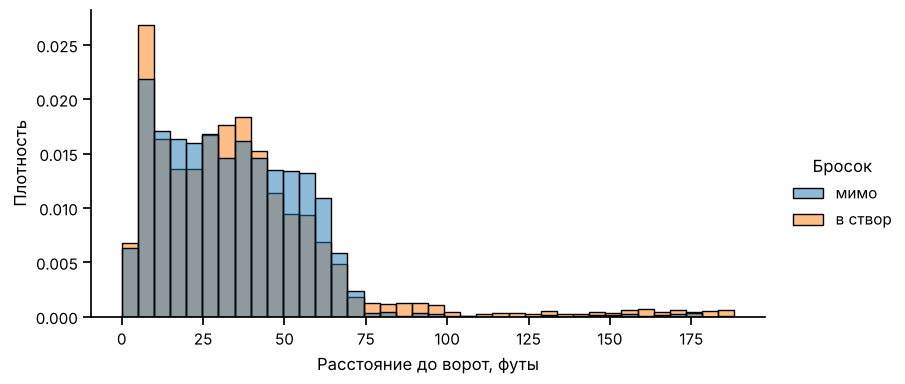

In [14]:
shots = events[is_shot].copy()
shots['Shot'] = 'в створ'
shots.loc[shots['Play Type'] == 'missed-shot', 'Shot'] = 'мимо'
print(shots['Shot'].value_counts())

g = sns.displot(data=shots, x='Shot Length', hue='Shot', hue_order=['мимо', 'в створ'],
                stat='density', common_norm=False, binwidth=5, height=4, aspect=2)
g.set_axis_labels('Расстояние до ворот, футы', 'Плотность')
g.legend.set_title('Бросок')
plt.show()

In [15]:
shots.groupby('Shot')['Shot Length'].describe()

,count,mean,std,min,25%,50%,75%,max
Shot,,,,,,,,
в створ,4623.000,36.207,29.997,0.000,15.000,31.828,47.011,188.215
мимо,2643.000,34.014,22.313,0.000,16.155,32.249,49.041,185.068


In [16]:
# доля бросков со своей половины площадки (дальше 89 футов) в каждой группе
(shots['Shot Length'] > 89).groupby(shots['Shot']).mean()

Shot
в створ   0.048
мимо      0.011
Name: Shot Length, dtype: float64

**Вывод.** В пределах зоны атаки распределения точных и неточных бросков очень похожи: медиана у обеих групп около 32 футов,
основная масса бросков — с 5–60 футов. Точные броски чуть чаще бывают совсем близко к воротам (до 10 футов), неточные —
чуть чаще с 50–60 футов. То есть расстояние само по себе слабо отличает точный бросок от неточного.
Главное различие — длинный правый хвост у точных бросков: со своей половины (дальше 89 футов) летят около 5% точных бросков
и только 1% неточных.

**Почему такой хвост**

1. Голы в пустые ворота. В конце матча проигрывающая команда снимает вратаря, и соперник бросает через всю площадку.
   Ниже видно, что голы со своей половины забиты почти все в 3-м периоде, в основном в последние минуты.
2. В НХЛ броском в створ считается любая шайба, которая летела в ворота и которую остановил вратарь. Поэтому выбросы и вбросы
   шайбы в зону «по воротам», которые вратарь просто ловит, записываются как `shot-on-goal`. А если такая же шайба проходит мимо
   ворот, её обычно не записывают как бросок — это просто вброс или проброс. Поэтому неточных дальних бросков почти нет.

In [17]:
long_goals = shots[(shots['Shot Length'] > 89) & (shots['Play Type'] == 'goal')]
print('Голов со своей половины:', len(long_goals), ', из них в 3-м периоде:', (long_goals['Period'] == 3).sum())
long_goals[['Game ID', 'Period', 'Elapsed Time', 'Team Making the Play', 'Shot Length']]

Голов со своей половины: 19 , из них в 3-м периоде: 18


,Game ID,Period,Elapsed Time,Team Making the Play,Shot Length
587,2025030112,2,16:29,Boston Bruins,89.090
2169,2025030116,3,16:40,Buffalo Sabres,89.051
10308,2025030161,3,16:52,Minnesota Wild,116.103
10669,2025030162,3,19:10,Dallas Stars,162.000
12162,2025030166,3,19:45,Minnesota Wild,167.431
12532,2025030171,3,18:21,Vegas Golden Knights,132.699
14565,2025030176,3,16:24,Vegas Golden Knights,120.266
15320,2025030182,3,18:50,Anaheim Ducks,129.000
15676,2025030183,3,18:27,Anaheim Ducks,172.569
18662,2025030216,3,14:12,Buffalo Sabres,158.152


## 10. Доля точных бросков у каждой команды в каждой игре

Считаем долю среди незаблокированных бросков (`shot-on-goal`, `goal`, `missed-shot`)

In [18]:
shots['On Goal'] = shots['Play Type'] != 'missed-shot'   # True для shot-on-goal и goal

numshots = shots.groupby(['Game ID', 'Team Making the Play'])['On Goal'].agg(['sum', 'count'])
numshots.columns = ['Shots on Goal', 'Unblocked Shots']
numshots['Share of Shots on Goal'] = numshots['Shots on Goal'] / numshots['Unblocked Shots']

numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins          0.625
            Buffalo Sabres         0.679
2025030112  Boston Bruins          0.614
            Buffalo Sabres         0.636
2025030113  Boston Bruins          0.694
                                    ... 
2025030414  Vegas Golden Knights   0.583
2025030415  Carolina Hurricanes    0.558
            Vegas Golden Knights   0.510
2025030416  Carolina Hurricanes    0.639
            Vegas Golden Knights   0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [19]:
numshots['Share of Shots on Goal'].describe()

count   164.000
mean      0.639
std       0.085
min       0.353
25%       0.583
50%       0.639
75%       0.689
max       0.860
Name: Share of Shots on Goal, dtype: float64

Интересно ещё проверить, бьют ли точнее те, кто выигрывает матч.

In [20]:
games['Winner'] = games['Home Team']
games.loc[games['Away Score'] > games['Home Score'], 'Winner'] = games['Away Team']

tmp = numshots.reset_index()
tmp['Won'] = tmp['Team Making the Play'] == tmp['Game ID'].map(games['Winner'])
tmp.groupby('Won')['Share of Shots on Goal'].mean()

Won
False   0.646
True    0.632
Name: Share of Shots on Goal, dtype: float64

**Вывод.** В среднем команда попадает в створ примерно в 64% незаблокированных бросков, в половине случаев доля лежит
между 0.58 и 0.69. Разброс между матчами большой — от 0.35 до 0.86. При этом победители бьют в створ не точнее проигравших
(0.632 против 0.646), так что точность бросков сама по себе исход матча, похоже, не определяет.

## 11. Команды с самой высокой и самой низкой средней долей точных бросков

In [21]:
avgnumshots = numshots['Share of Shots on Goal'].groupby('Team Making the Play').mean()

# сколько матчей сыграла каждая команда - пригодится для комментария и в п. 12
team_games = pd.concat([games['Home Team'], games['Away Team']]).value_counts()

print(avgnumshots.nlargest(5))
print()
print(avgnumshots.nsmallest(5))

Team Making the Play
Edmonton Oilers       0.706
Philadelphia Flyers   0.684
Dallas Stars          0.670
Minnesota Wild        0.656
Colorado Avalanche    0.653
Name: Share of Shots on Goal, dtype: float64

Team Making the Play
Pittsburgh Penguins   0.554
Utah Mammoth          0.599
Carolina Hurricanes   0.615
Tampa Bay Lightning   0.626
Buffalo Sabres        0.626
Name: Share of Shots on Goal, dtype: float64


In [22]:
pd.DataFrame({'Share': avgnumshots, 'Games': team_games}).sort_values('Share', ascending=False)

,Share,Games
Edmonton Oilers,0.706,6
Philadelphia Flyers,0.684,10
Dallas Stars,0.670,6
Minnesota Wild,0.656,11
Colorado Avalanche,0.653,13
Anaheim Ducks,0.649,12
Montréal Canadiens,0.644,19
Los Angeles Kings,0.642,4
Boston Bruins,0.638,6
Ottawa Senators,0.635,4


**Комментарий.** Разница между самыми точными и самыми неточными командами около 15 п.п.: 0.71 у Эдмонтона против 0.55
у Питтсбурга. Но выборки маленькие: Эдмонтон, Даллас и Питтсбург сыграли всего по 6 матчей, тогда как Вегас — 22, а Каролина — 19,
так что средние у команд, рано вылетевших, гораздо шумнее. Любопытно, что Каролина, которая выиграла Кубок (см. дополнительный раздел),
оказалась в пятёрке самых неточных — она берёт скорее количеством бросков (п. 12), чем точностью. А Питтсбург с худшей точностью
вылетел в первом раунде.

## 12. Среднее число бросков в створ и голов за игру

Гол тоже считается броском в створ (так считает и НХЛ), поэтому для `Shot` беру `shot-on-goal` + `goal`. Делю на число сыгранных командой матчей (`team_games` из прошлого пункта).

In [23]:
team_shots = events[events['Play Type'].isin(['shot-on-goal', 'goal'])].groupby('Team Making the Play').size()
team_goals = events[events['Play Type'] == 'goal'].groupby('Team Making the Play').size()

avgshots = pd.DataFrame({'Shot': team_shots / team_games,
                         'Goal': team_goals / team_games})
avgshots.index.name = 'Team Making the Play'
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


## 13. Связь бросков в створ и голов

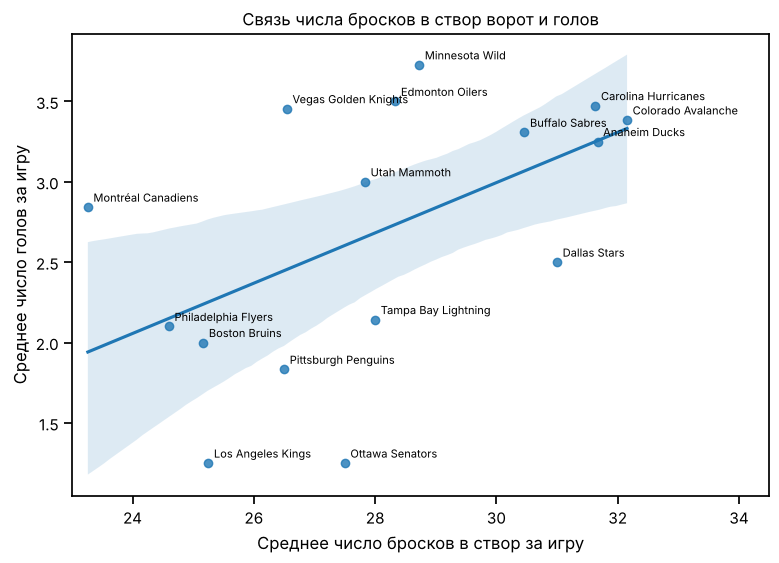

In [24]:
plt.figure(figsize=(9, 6))
sns.regplot(x='Shot', y='Goal', data=avgshots)
for team in avgshots.index:
    plt.annotate(team, (avgshots.loc[team, 'Shot'], avgshots.loc[team, 'Goal']),
                 xytext=(4, 4), textcoords='offset points', fontsize=8)
plt.xlim(23, 34.5)   # чтобы подписи справа не обрезались
plt.xlabel('Среднее число бросков в створ за игру')
plt.ylabel('Среднее число голов за игру')
plt.title('Связь числа бросков в створ ворот и голов')
plt.show()

In [25]:
print(avgshots.corr())

# наклон линии регрессии
slope, intercept = np.polyfit(avgshots['Shot'], avgshots['Goal'], 1)
print('наклон:', round(slope, 3))

      Shot  Goal
Shot 1.000 0.521
Goal 0.521 1.000
наклон: 0.156


**Вывод.** Связь положительная: наклон около 0.16, т.е. +1 бросок в створ за игру в среднем даёт примерно +0.16 гола.
Корреляция 0.52 — умеренная. Но точек всего 16, доверительный интервал широкий, и несколько команд сильно выбиваются:
Оттава и Лос-Анджелес бросали много, а забивали по 1.25 гола за игру (обе проиграли в первом раунде всухую),
а Монреаль бросал меньше всех, но забивал почти 3 гола за игру. Так что связь видна, но слабая: кроме количества бросков
важно их качество (откуда бьют) и игра вратаря соперника.

## 14. Матч с наибольшим числом ударов по воротам

Считаем все удары: в створ, голы, мимо и заблокированные.

In [51]:
attempt_types = ['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot']
attempts = events[events['Play Type'].isin(attempt_types)]

attempts_per_game = attempts.groupby('Game ID').size()
idxmax = attempts_per_game.idxmax()

print(attempts_per_game.max(), 'ударов')
print(gameInfo(idxmax))

208 ударов
Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


In [52]:
# топ-3 для сравнения
for game_id in attempts_per_game.nlargest(3).index:
    print(attempts_per_game[game_id], gameInfo(game_id))

208 Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
169 Minnesota Wild - Dallas Stars (3 - 2, Final/OT, 2026-04-25)
163 Vegas Golden Knights - Carolina Hurricanes (5 - 4, Final/2OT, 2026-06-06)


Логично, что это матч с двумя овертаймами: последний гол забит на 14-й минуте 5-го периода, т.е. играли почти 94 минуты
вместо 60. Следующие два матча по числу ударов тоже овертаймовые.

## 15. Карта ударов в этом матче

Команды меняются сторонами каждый период. Сначала посмотрим, где ворота хозяев в каждом периоде этого матча:

In [53]:
game_shots = attempts[attempts['Game ID'] == idxmax].copy()
game_shots.groupby('Period')["Home Team's Defending Side"].first()

Period
1    right
2     left
3    right
4     left
5    right
Name: Home Team's Defending Side, dtype: object

В нечётных периодах ворота хозяев справа, т.е. хозяева бьют в левые ворота. Поэтому, как и сказано в задании, в нечётных периодах
переворачиваю координаты $(x, y) \mapsto (-x, -y)$ — тогда хозяева (Каролина) всегда бьют вправо, а гости (Оттава) — влево.

Для `blocked-shot` в `Team Making the Play` записана команда, чей бросок заблокировали (как в таблице 3 задания), так что
раскраска по командам правильная. Координаты у заблокированных бросков — это место блока.

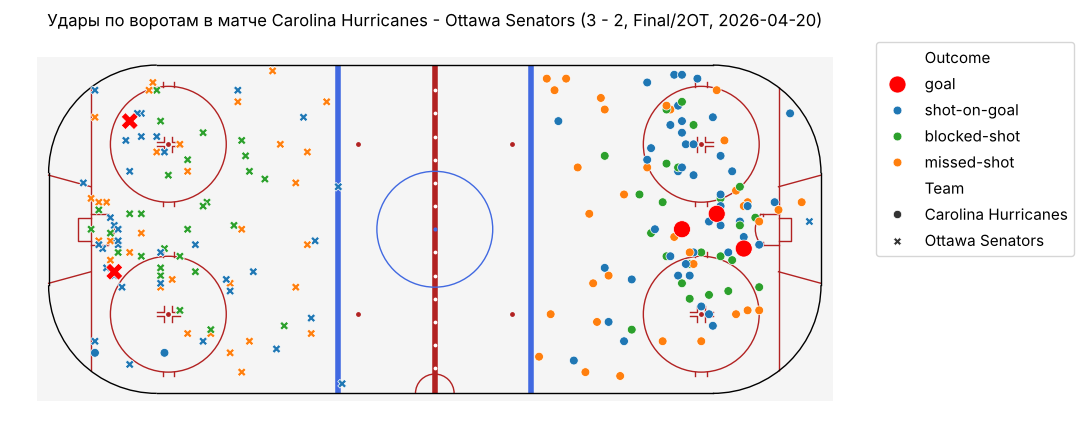

In [29]:
game_shots['x'] = game_shots['X Coordinate on the Ice Rink']
game_shots['y'] = game_shots['Y Coordinate on the Ice Rink']

odd = game_shots['Period'] % 2 == 1
game_shots.loc[odd, 'x'] = -game_shots.loc[odd, 'x']
game_shots.loc[odd, 'y'] = -game_shots.loc[odd, 'y']

game_shots['Outcome'] = game_shots['Play Type']
game_shots['Team'] = game_shots['Team Making the Play']

# голов всего 5, поэтому рисую их последними (поверх остальных) и крупнее
game_shots['Is Goal'] = game_shots['Outcome'] == 'goal'
game_shots = game_shots.sort_values('Is Goal')

colors = {'goal': 'red', 'shot-on-goal': 'tab:blue', 'blocked-shot': 'tab:green', 'missed-shot': 'tab:orange'}
sizes = {'goal': 150, 'shot-on-goal': 40, 'blocked-shot': 40, 'missed-shot': 40}

plt.figure(figsize=(11, 4.5))
plot_rink()
sns.scatterplot(x='x', y='y', data=game_shots, hue='Outcome', style='Team', size='Outcome',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                palette=colors, sizes=sizes)
plt.axis('equal')
plt.axis('off')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.title('Удары по воротам в матче ' + gameInfo(idxmax))
plt.tight_layout()
plt.show()

In [30]:
pd.crosstab(game_shots['Team'], game_shots['Outcome'], margins=True)

Outcome,blocked-shot,goal,missed-shot,shot-on-goal,All
Team,,,,,
Carolina Hurricanes,26,3,34,46,109
Ottawa Senators,28,2,32,37,99
All,54,5,66,83,208


**Комментарий.** У Каролины ударов больше (109 против 99), и в створ она попадала чаще (46 бросков в створ против 37).
Все пять голов забиты с близкой дистанции — от 9 до 27 футов, т.е. из слота и с кругов вбрасывания; победный гол во втором овертайме
забит с 25 футов прямо по центру. Промахи в среднем летят дальше всего, а заблокированные броски останавливаются примерно в 25–30 футах
от ворот (это место блока, сам бросок был дальше). Отдельные точки на своей половине — дальние выбросы шайбы, которые вратарь
ловит и которые записаны как броски в створ (см. п. 9).

## 16. Лучшие снайперы

Здесь и дальше ставлю `keep='all'` в `nlargest`: если у нескольких игроков одинаковое значение на 10-м месте, выводятся все,
иначе выбор между ними был бы случайным.

In [31]:
goals = events[events['Play Type'] == 'goal'].copy()

player_goals = goals['Player in the Event #1'].value_counts()
player_goals.nlargest(10, keep='all')

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Matt Boldy           7
Mark Stone           7
Name: count, dtype: int64

## 17. Лучшие голевые передачи

Передачи — это Player #2 и Player #3 в голах, склеиваю две колонки в одну.

In [32]:
player_assists = pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']]).value_counts()
player_assists.nlargest(10, keep='all')

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: count, dtype: int64

## 18. Гол + пас

При равенстве очков сортирую по голам (так делает НХЛ).

In [33]:
points = pd.DataFrame({'Goals': player_goals, 'Assists': player_assists}).fillna(0).astype(int)
points['Points'] = points['Goals'] + points['Assists']

points.nlargest(10, 'Points', keep='all').sort_values(['Points', 'Goals'], ascending=False)

,Goals,Assists,Points
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Pavel Dorofeyev,12,4,16
Logan Stankoven,11,5,16
Nick Suzuki,4,12,16


Лучший снайпер — Brett Howden (14 голов), лучший ассистент — Jack Eichel (20 передач), лучший по очкам — Mitch Marner (10 + 19 = 29).
Все трое из Вегаса, который сыграл больше всех матчей (22) — в абсолютных числах это даёт заметное преимущество.

## 19. Броски в створ за игру

«В среднем за игру» понимаю как число бросков в створ (опять `shot-on-goal` + `goal`), делённое на число матчей, которые
игрок сыграл. Сыгранные матчи считаю по колонкам с составами на льду: если игрок хоть раз был на льду в матче, значит, играл.
(Если делить только на матчи, где игрок бросал, среднее завышается у тех, кто бросает редко.)

In [34]:
# пары (матч, игрок) из всех колонок с составами
pairs = []
for col in player_cols:
    df = events[['Game ID', col]].dropna()
    df.columns = ['Game ID', 'Player']
    pairs.append(df)
pairs = pd.concat(pairs).drop_duplicates()

games_played = pairs['Player'].value_counts()
print(len(games_played), 'игроков')
games_played.describe()

372 игроков


count   372.000
mean      8.403
std       5.651
min       1.000
25%       4.000
50%       6.000
75%      12.000
max      22.000
Name: count, dtype: float64

In [35]:
player_shots = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]['Player in the Event #1'].value_counts()

players = pd.DataFrame({'Games': games_played, 'Shots on Goal': player_shots}).fillna(0)
players['Shots per Game'] = players['Shots on Goal'] / players['Games']

players.nlargest(10, 'Shots per Game')

,Games,Shots on Goal,Shots per Game
Jason Robertson,6,30.000,5.000
Dylan Guenther,6,27.000,4.500
Nikita Kucherov,7,31.000,4.429
Matt Boldy,11,48.000,4.364
Quinton Byfield,4,17.000,4.250
Darren Raddysh,7,28.000,4.000
Joel Eriksson Ek,6,24.000,4.000
Alex Laferriere,4,15.000,3.750
David Pastrnak,6,22.000,3.667
Nathan MacKinnon,13,47.000,3.615


Все игроки из топ-10 сыграли минимум 4 матча (самая короткая серия), так что это не случайные одиночные игры.

## 20. Силовые приёмы за игру

In [36]:
player_hits = events[events['Play Type'] == 'hit']['Player in the Event #1'].value_counts()

players['Hits'] = player_hits
players['Hits'] = players['Hits'].fillna(0)
players['Hits per Game'] = players['Hits'] / players['Games']

players.nlargest(10, 'Hits per Game')[['Games', 'Hits', 'Hits per Game']]

,Games,Hits,Hits per Game
Lawson Crouse,6,38.000,6.333
Alex Turcotte,1,6.000,6.000
Alexander Petrovic,1,6.000,6.000
Yakov Trenin,9,51.000,5.667
Dylan Cozens,4,22.000,5.500
Vasily Podkolzin,6,32.000,5.333
Carl Grundstrom,3,15.000,5.000
Ivan Barbashev,22,110.000,5.000
Marcus Foligno,11,55.000,5.000
Owen Tippett,6,29.000,4.833


Здесь в топ попали двое, кто сыграл всего один матч (по 6 силовых приёмов). Если оставить только тех, кто сыграл хотя бы
4 матча (минимальная длина серии), список становится показательнее:

In [37]:
players[players['Games'] >= 4].nlargest(10, 'Hits per Game')[['Games', 'Hits', 'Hits per Game']]

,Games,Hits,Hits per Game
Lawson Crouse,6,38.000,6.333
Yakov Trenin,9,51.000,5.667
Dylan Cozens,4,22.000,5.500
Vasily Podkolzin,6,32.000,5.333
Ivan Barbashev,22,110.000,5.000
Marcus Foligno,11,55.000,5.000
Owen Tippett,6,29.000,4.833
William Carrier,19,91.000,4.789
Colton Dach,5,23.000,4.600
Cole Smith,22,100.000,4.545


## 21. Вратари, которые хотя бы в одном матче не пропустили ни одного гола

Для каждого гола нужно найти вратаря, который в этот момент стоял в воротах пропустившей команды, посчитать пропущенные
голы для каждой пары (матч, вратарь) и найти пары с нулём. Пары (матч, вратарь) беру из колонок вратарей по всем событиям,
так что вратари, которые выходили на замену, тоже учитываются.

In [38]:
goalie_cols = ["Away Team's Goalie", "Home Team's Goalie"]

appearances = pd.concat([events[['Game ID', goalie_cols[0]]].rename(columns={goalie_cols[0]: 'Goalie'}),
                         events[['Game ID', goalie_cols[1]]].rename(columns={goalie_cols[1]: 'Goalie'})])
appearances = appearances.dropna().drop_duplicates()
print(len(appearances), 'выходов вратарей,', appearances['Goalie'].nunique(), 'разных вратарей')


def zero_goals(goals):
    # goals['Goalie'] - вратарь, который пропустил гол (NaN, если ворота были пустые)
    conceded = goals.dropna(subset=['Goalie']).groupby(['Game ID', 'Goalie']).size()
    table = appearances.set_index(['Game ID', 'Goalie'])
    table['Goals Against'] = conceded
    table['Goals Against'] = table['Goals Against'].fillna(0).astype(int)
    return table

174 выходов вратарей, 25 разных вратарей


Сначала в лоб: беру вратаря из той же строки, где записан гол. Если забили хозяева, то пропустил вратарь гостей, и наоборот.

In [39]:
home_scored = goals['Team Making the Play'] == goals['Home Team']
goals['Goalie'] = np.where(home_scored, goals[goalie_cols[0]], goals[goalie_cols[1]])

table = zero_goals(goals)
table[table['Goals Against'] == 0]

,,Goals Against
Game ID,Goalie,
2025030126,Andrei Vasilevskiy,0
2025030142,Dan Vladar,0
2025030146,Arturs Silovs,0
2025030314,Frederik Andersen,0
2025030413,Brandon Bussi,0
2025030416,Brandon Bussi,0
2025030114,Joonas Korpisalo,0
2025030126,Jakub Dobes,0
2025030131,Frederik Andersen,0


**А тут какая-то шняга**. Например, по этой таблице и Василевский, и Добеш (Jakub Dobes) отыграли на ноль матч 2025030126,
хотя он закончился 1:0 в овертайме. Посмотрим на этот гол:

In [40]:
cols = ['Game ID', 'Period', 'Elapsed Time', 'Team Making the Play', 'Cumulated Away Score', 'Cumulated Home Score',
        "# of Away Team's Players on the Ice", "# of Home Team's Players on the Ice"] + goalie_cols
goals.loc[goals['Game ID'] == 2025030126, cols]

,Game ID,Period,Elapsed Time,Team Making the Play,Cumulated Away Score,Cumulated Home Score,# of Away Team's Players on the Ice,# of Home Team's Players on the Ice,Away Team's Goalie,Home Team's Goalie
4351,2025030126,4,09:03,Tampa Bay Lightning,1,0,0,0,NaN,NaN


У гола в овертайме на льду 0 игроков и нет вратарей. Похоже, состав в строке гола записан уже **после** гола: после
победного гола в овертайме игра закончилась, и на льду никого нет. Это же объясняет ещё две проблемы:

* голы в пустые ворота: к моменту записи вратарь уже вернулся на лёд, и гол «записывается» на него (например, гол Далласа
  со 162 футов на 19:10 третьего периода в матче 2025030162 — явно в пустые ворота, но в строке стоит вратарь);
* замены вратаря после гола: в строке уже стоит сменщик, хотя гол пропустил тот, кого заменили.

Проверим на всех голах, что видно в строке гола и в предыдущем событии:

In [41]:
prev = events.groupby('Game ID')[goalie_cols].shift(1)   # составы на предыдущем событии того же матча

prev_goals = prev.loc[goals.index]
goals['Prev Goalie'] = np.where(home_scored, prev_goals[goalie_cols[0]], prev_goals[goalie_cols[1]])

no_players = goals["# of Away Team's Players on the Ice"] == 0
print('Голов, где на льду 0 игроков:', no_players.sum())
print('  из них в овертайме:', (goals.loc[no_players, 'Period'] > 3).sum())
print('Вратаря нет в строке гола:', goals['Goalie'].isna().sum())
print('Вратаря нет на предыдущем событии (пустые ворота):', goals['Prev Goalie'].isna().sum())
different = goals['Goalie'].fillna('-') != goals['Prev Goalie'].fillna('-')
print('Вратарь в строке гола и до гола разный:', different.sum())

Голов, где на льду 0 игроков: 22
  из них в овертайме: 22
Вратаря нет в строке гола: 25
Вратаря нет на предыдущем событии (пустые ворота): 34
Вратарь в строке гола и до гола разный: 58


Все 22 гола без состава — это победные голы в овертаймах (столько же было овертаймовых матчей). Поэтому вратаря, пропустившего гол,
беру из предыдущего события в том же матче — там состав соответствует моменту перед голом. Тогда голов в пустые ворота
получается 34, а не 25, — это похоже на правду, если вспомнить дальние голы в концовках третьих периодов из п. 9.

In [42]:
goals['Goalie'] = goals['Prev Goalie']

table = zero_goals(goals)
# проверка: пропущенные вратарями + голы в пустые ворота = все голы
print(table['Goals Against'].sum() + goals['Goalie'].isna().sum(), '=', len(goals))

shutouts = table[table['Goals Against'] == 0].reset_index()
shutouts['Game Info'] = shutouts['Game ID'].map(gameInfo)
shutouts.sort_values('Goalie')

486 = 486


,Game ID,Goalie,Goals Against,Game Info
5,2025030112,Alex Lyon,0,"Buffalo Sabres - Boston Bruins (2 - 4, Final, 2026-04-21)"
0,2025030126,Andrei Vasilevskiy,0,"Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)"
4,2025030416,Brandon Bussi,0,"Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)"
1,2025030142,Dan Vladar,0,"Pittsburgh Penguins - Philadelphia Flyers (0 - 3, Final, 2026-04-20)"
8,2025030146,Dan Vladar,0,"Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)"
3,2025030314,Frederik Andersen,0,"Montréal Canadiens - Carolina Hurricanes (0 - 4, Final, 2026-05-27)"
7,2025030131,Frederik Andersen,0,"Carolina Hurricanes - Ottawa Senators (2 - 0, Final, 2026-04-18)"
9,2025030221,Frederik Andersen,0,"Carolina Hurricanes - Philadelphia Flyers (3 - 0, Final, 2026-05-02)"
6,2025030114,Joonas Korpisalo,0,"Boston Bruins - Buffalo Sabres (1 - 6, Final, 2026-04-26)"
10,2025030235,Scott Wedgewood,0,"Colorado Avalanche - Minnesota Wild (4 - 3, Final/OT, 2026-05-13)"


In [43]:
print('Вратари, которые хотя бы в одном матче не пропустили ни одного гола:')
for name in sorted(shutouts['Goalie'].unique()):
    print(name)

Вратари, которые хотя бы в одном матче не пропустили ни одного гола:
Alex Lyon
Andrei Vasilevskiy
Brandon Bussi
Dan Vladar
Frederik Andersen
Joonas Korpisalo
Scott Wedgewood
Ukko-Pekka Luukkonen


**Ответ:** 8 вратарей. Полные «сухие» матчи — у Василевского, Владара (дважды), Андерсена (трижды) и Бусси.
Остальные (Alex Lyon, Joonas Korpisalo, Ukko-Pekka Luukkonen, Scott Wedgewood) не пропустили, выйдя на замену.
По сравнению с решением в лоб ушли Добеш и Силовс (проиграли свои матчи в овертайме) и добавились Лайон и Луукконен:
раньше на них ошибочно записывались голы, пропущенные вратарём, которого они заменили.

## 22. Свой вопрос: насколько важно забить первым и есть ли преимущество своей площадки?

Хочу проверить три вещи:

1. Как часто выигрывает команда, которая открыла счёт?
2. Как часто выигрывает команда, которая ведёт после двух периодов?
3. Помогает ли в плей-офф игра дома?

In [44]:
# goals отсортированы по времени, поэтому первый гол в каждом матче - это first()
games['First Goal'] = goals.groupby('Game ID')['Team Making the Play'].first()
games['First Goal Won'] = games['First Goal'] == games['Winner']

print('Команда, открывшая счёт, выиграла', games['First Goal Won'].sum(), 'матчей из', len(games))
print('Доля:', round(games['First Goal Won'].mean(), 3))

Команда, открывшая счёт, выиграла 56 матчей из 82
Доля: 0.683


In [45]:
# счёт после двух периодов берём из события period-end 2-го периода
end2 = events[(events['Play Type'] == 'period-end') & (events['Period'] == 2)].set_index('Game ID')
diff2 = end2['Cumulated Home Score'] - end2['Cumulated Away Score']

games['After 2'] = 'ничья'
games.loc[diff2[diff2 > 0].index, 'After 2'] = 'ведут хозяева'
games.loc[diff2[diff2 < 0].index, 'After 2'] = 'ведут гости'

games['Home Win'] = games['Home Score'] > games['Away Score']
pd.crosstab(games['After 2'], games['Home Win'], margins=True)

Home Win,False,True,All
After 2,,,
ведут гости,25,8,33
ведут хозяева,3,21,24
ничья,15,10,25
All,43,39,82


открыла счёт            0.683
вела после 2 периодов   0.807
играла дома             0.476
dtype: float64


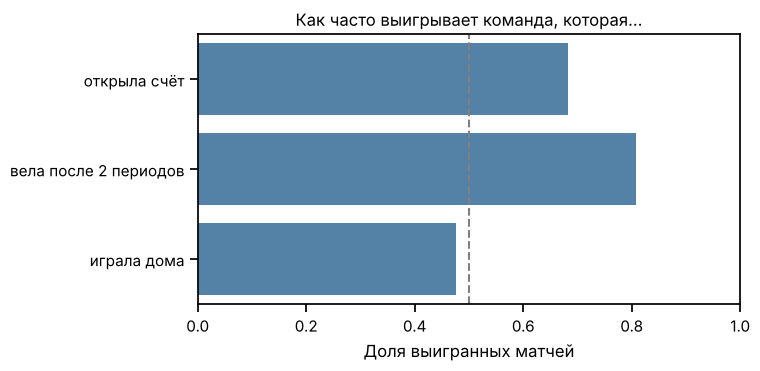

In [46]:
leader = games[games['After 2'] != 'ничья']
home_leads = leader['After 2'] == 'ведут хозяева'
# лидер выиграл, если вели хозяева и они победили, или вели гости и хозяева проиграли
leader_won = (home_leads & leader['Home Win']) | (~home_leads & ~leader['Home Win'])

summary = pd.Series({'открыла счёт': games['First Goal Won'].mean(),
                     'вела после 2 периодов': leader_won.mean(),
                     'играла дома': games['Home Win'].mean()})
print(summary)

plt.figure(figsize=(7, 3.5))
sns.barplot(x=summary.values, y=summary.index, color='steelblue')
plt.axvline(0.5, color='grey', linestyle='--')
plt.xlim(0, 1)
plt.xlabel('Доля выигранных матчей')
plt.ylabel('')
plt.title('Как часто выигрывает команда, которая...')
plt.show()

In [47]:
# а в овертаймах?
pd.crosstab(games['Outcome'], games['Home Win'], margins=True)

Home Win,False,True,All
Outcome,,,
Final,35,25,60
Final/2OT,1,3,4
Final/OT,7,11,18
All,43,39,82


**Вывод.** Первый гол важен: команда, открывшая счёт, выиграла 56 матчей из 82 (68%). Ведущая после двух периодов команда
выигрывает ещё чаще — 81% (46 из 57 матчей, где после двух периодов не было ничьей), причём хозяева, ведя после двух периодов,
упустили победу только 3 раза из 24.
А вот преимущества своей площадки в этом плей-офф не видно: хозяева выиграли только 39 матчей из 82 (47.6%), это даже меньше
половины. Разве что в овертаймах хозяева выигрывали чаще (14 из 22), но таких матчей слишком мало, чтобы делать выводы.